# CAP182 SS3 Part B - Applying the final method to STADIOEquities client data

**Author:** Vusumuzi Nkosi  **Student number:** 26303296
**Module:** CAP182 Capstone Project, STADIO  **Client:** STADIOEquities

The implementation in this notebook uses the last model selected in SS2 for the whole dataset of the clients.

**Business problem (from SS1).** For every new STADIOEquities user that registers for their account, determine if there will be any deposits made by the user within 30 days from the date of registration. The prediction should be done no more than 24 hours after registration, therefore only account-based, KYC, and behavior up to the first 24 hours can be used as features. Any other information beyond this cut-off time will only be used for creating the label.

**Final method (from SS2).** XGBoost, which is the better performing one out of the two SS2 models (AUC ROC 0.8090 versus 0.8020; AUC PR 0.4868 versus 0.4591; McNemar p = 5.8e-8), is incorporated into the pipeline, including features engineering, column-based pre-processing and the classifier itself using scale_pos_weight.

### Contents

| Section | Contents |
|---|---|
| 0 | Environment and configuration |
| 1 | Loading of dataset |
| 2 | Pre-processing of dataset |
| 3 | Training of model |
| 4 | Validating of model |
| 5 | Visualisation of results |
| 6 | Summary |

## Section 0 - Environment and configuration

Dependencies that emerge from the dataset schema are all captured under one place to ensure that no changes are made to the other sections of the notebook while verifying the column names.

In [1]:
import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import xgboost
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost     ", xgboost.__version__)
print("matplotlib  ", matplotlib.__version__)

pandas       3.0.5
numpy        2.5.2
scikit-learn 1.9.0
xgboost      3.4.1
matplotlib   3.11.1


In [2]:
# Repository paths. The notebook lives at the repository root.
REPO_DIR    = Path.cwd()
SCRIPTS_DIR = REPO_DIR / "scripts"
CLIENT_DIR  = REPO_DIR / "datasets" / "client"
RESULTS_DIR = REPO_DIR / "experimental-results"
MODELS_DIR  = REPO_DIR / "models"
for d in (RESULTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Reuse the SS2 components that are dataset-agnostic.
import sys
sys.path.insert(0, str(SCRIPTS_DIR))
from preprocessing import build_preprocessor   # noqa: E402
from evaluate import compute_metrics           # noqa: E402

RANDOM_STATE = 42          # same seed as SS2
PROBA_THRESHOLD = 0.50     # same default decision threshold as SS2; revisited in Section 4

print("Client data folder:", CLIENT_DIR)
print("Files present:", sorted(p.name for p in CLIENT_DIR.glob("*")) if CLIENT_DIR.exists() else "folder not created yet")

Client data folder: /Users/vusizwe/Desktop/Cowork Home/Final Semester Work/CAP182/cap182-capstone/datasets/client
Files present: ['DATA_DICTIONARY.md', 'QUALITY_CONTROLS.md', 'README.md', 'table1_account_and_funding.csv', 'table2_app_web_behaviour.csv', 'table3_client_demographics.csv', 'table4_marketing_communication.csv', 'table5_kyc_compliance_events.csv', 'table6_support_feedback.csv', 'table7_product_subscription.csv', 'table8_funding_attempts.csv']


In [3]:
# ---------------------------------------------------------------------------
# Configuration for extracting client. The configuration above has been validated against the data dictionary
# (v1.0) and the profiling executed on 28th September 2026.
# ---------------------------------------------------------------------------

# The extract lives in the directory datasets/client/ within the repository. When working outside
# of the repository, the extract is loaded from the delivery directory.
_CANDIDATES = [
    CLIENT_DIR,
    Path.home() / "Desktop/Cowork Home/Final Semester Work/CAP182"
                  "/nkosivusumuzi_client_data/stadioequities",
    Path("../../nkosivusumuzi_client_data/stadioequities"),
]
CLIENT_DIR = next((d for d in _CANDIDATES
                   if (Path(d) / "table1_account_and_funding.csv").exists()), CLIENT_DIR)
CLIENT_DIR = Path(CLIENT_DIR)

CLIENT_FILES = {
    "accounts":    CLIENT_DIR / "table1_account_and_funding.csv",
    "sessions":    CLIENT_DIR / "table2_app_web_behaviour.csv",
    "demographics":CLIENT_DIR / "table3_client_demographics.csv",
    "marketing":   CLIENT_DIR / "table4_marketing_communication.csv",
    "kyc":         CLIENT_DIR / "table5_kyc_compliance_events.csv",
    "support":     CLIENT_DIR / "table6_support_feedback.csv",
    "products":    CLIENT_DIR / "table7_product_subscription.csv",
    "deposits":    CLIENT_DIR / "table8_funding_attempts.csv",
}

KEY_COL    = "Account ID"
REG_TS_COL = "Registration time"
DEADLINE   = "Activation deadline"
TARGET     = "Activated 30d"

ACTIVATION_WINDOW_DAYS = 30    # registration -> Activation deadline
FEATURE_CUTOFF_HOURS   = 24    # SS1 scoring cut-off

# Modelling cohort. See the markdown below for the reasoning.
COHORT_STATUS = "complete"

# Never used as predictors. The first group is the dictionary's own forbidden
# list; the second was added by profiling.
LEAKAGE_COLUMNS = [
    # Table 1, outcome or outcome-building
    "First deposit time", "First deposit amount", "First deposit status",
    "Activated 30d", "Funding event ID", "Activation deadline",
    # Table 1, measured after the outcome
    "Current balance", "Closure time", "Extract time",
    # added by profiling: an extract-time snapshot that encodes the outcome
    "Registration status",
]

print("Client data folder:", CLIENT_DIR)
print("Files found:", sum((Path(v).exists()) for v in CLIENT_FILES.values()), "of", len(CLIENT_FILES))

Client data folder: /Users/vusizwe/Desktop/Cowork Home/Final Semester Work/CAP182/cap182-capstone/datasets/client
Files found: 8 of 8


---

## Section 1 - DATASET LOADING

A full extract has been provided by the client. From the brief, it is clear that this extract may have information that is not relevant to the problem being solved; hence, this segment does three things: (i) imports the tables, (ii) identifies which tables are used and why, and (iii) provides information on the size, classes, and class imbalance.

In [4]:
def load_client_tables(files: dict) -> dict:
    """Load each supplied client table and report its shape."""
    tables = {}
    for name, path in files.items():
        path = Path(path)
        if not path.exists():
            print(f"  MISSING  {name:12s} {path}")
            continue
        frame = pd.read_csv(path, low_memory=False)
        tables[name] = frame
        print(f"  loaded   {name:13s} {frame.shape[0]:>7,} rows x {frame.shape[1]:>2} cols  ({path.name})")
    return tables

tables = load_client_tables(CLIENT_FILES)

  loaded   accounts        1,841 rows x 15 cols  (table1_account_and_funding.csv)
  loaded   sessions        7,142 rows x 15 cols  (table2_app_web_behaviour.csv)
  loaded   demographics    1,841 rows x 11 cols  (table3_client_demographics.csv)
  loaded   marketing      11,090 rows x 12 cols  (table4_marketing_communication.csv)
  loaded   kyc            13,632 rows x 11 cols  (table5_kyc_compliance_events.csv)
  loaded   support           828 rows x 12 cols  (table6_support_feedback.csv)
  loaded   products        2,195 rows x 11 cols  (table7_product_subscription.csv)
  loaded   deposits        1,532 rows x 10 cols  (table8_funding_attempts.csv)


In [5]:
# --- Integrity checks against the supplied quality pack --------------------------
PRIMARY_KEYS = {
    "accounts": "Account ID", "sessions": "Session ID", "demographics": "Account ID",
    "marketing": "Event ID", "kyc": "Compliance event ID", "support": "Interaction ID",
    "products": "Relationship ID", "deposits": "Deposit ID",
}
account_ids = set(tables["accounts"][KEY_COL])

print(f"{'table':14s} {'rows':>8s} {'dup keys':>9s} {'dup rows':>9s} {'null acct':>10s} {'orphans':>8s}")
for name, df in tables.items():
    pk = PRIMARY_KEYS[name]
    dup_keys = int(df[pk].duplicated().sum())
    dup_rows = int(df.duplicated().sum())
    if KEY_COL in df.columns:
        null_acct = int(df[KEY_COL].isna().sum())
        orphans = int((~df[KEY_COL].isin(account_ids) & df[KEY_COL].notna()).sum())
    else:
        null_acct = orphans = 0
    print(f"{name:14s} {len(df):>8,} {dup_keys:>9d} {dup_rows:>9d} {null_acct:>10d} {orphans:>8d}")

print("\nThe null Account IDs in marketing are the documented anonymous "
      "pre-registration touchpoints, not defects.")

table              rows  dup keys  dup rows  null acct  orphans
accounts          1,841         0         0          0        0
sessions          7,142         0         0          0        0
demographics      1,841         0         0          0        0
marketing        11,090         0         0        458        0
kyc              13,632         0         0          0        0
support             828         0         0          0        0
products          2,195         0         0          0        0
deposits          1,532         0         0          0        0

The null Account IDs in marketing are the documented anonymous pre-registration touchpoints, not defects.


### Which tables are used, and why (data format justification)

The client has provided us with eight CSV tables and a data dictionary, and a reconciliation package. The assignment states that the extract includes some data which is not related to the current task; therefore, each table is analyzed against the SS1 problem statement before usage.

| Table | Rows | Used | Reason |
|---|---:|---|---|
| 1 account_and_funding | 1,841 | **yes**, split | Includes the registration event, account attributes available at sign-up and the provided target. Fields after the outcome are excluded from predictors. |
| 2 app_web_behaviour | 7,142 | **yes** | Captures the first-24-hour behaviour, the main component of SS1 hypothesis. Covers 100% of accounts within the cutoff. |
| 3 client_demographics | 1,841 | **yes** | Attributes known at registration, one record per account, covers 100% of accounts. |
| 4 marketing_communication | 11,090 | **yes**, partial | Acquisition context. Sparse data, covers 28% of accounts, so we should explicitly include the "none" level. |
| 5 kyc_compliance_events | 13,632 | **yes** | On-boarding friction during the cutoff. Covers 100% of accounts. |
| 6 support_feedback | 828 | **no** | Only 15 accounts have a ticket within the 24-hour cutoff, feature engineering will be impossible without artificial signal. |
| 7 product_subscription | 2,195 | **yes**, partial | Stated goal and product choice, covers 17% of accounts within the cutoff, "none" level included. |
| 8 funding_attempts | 1,532 | **label only** | Data dictionary suggests that this is the target-building table and excludes all columns as predictors. |

All tables are connected with `Account ID`, the stable pseudonym required by the SS1 data protocol, and, therefore, the usage of direct identifiers is not needed. Data are provided in UTF-8 CSV format with ISO 8601 timestamps with the `+02:00` offset and monetary values in cents. Therefore, all timestamps are parsed with explicit format instead of guessing.

### Cohort decision

Variable "Registration status" separates our extract precisely:

| Registration status | Accounts | Activation rate |
|---|---:|---:|
| complete | 1,133 | 62.6% |
| cancelled | 93 | 2.2% |
| closed | 72 | 1.4% |
| incomplete | 416 | 0.2% |
| rejected | 127 | 0.0% |

Totally, 708 accounts (38%) have an outcome which is known in advance: an account which never completes registration, or which is rejected, cancelled or closed cannot fund. Therefore, it does not make sense to predict their funding status and including such accounts will make the model learn proxies for the label instead of the actual behavior.

Registration status is a snapshot at the moment of extraction, not 24 hours after registration, and the combination "closed"-"closure time" is forbidden by the dictionary. So, this variable is excluded as a predictor and as a part of the cohort definition.

We fit the model on 1,133 complete registrations. All other 708 accounts represent an operational rule, not a predicted outcome.

In [6]:
# --- Target and modelling cohort -------------------------------------------------
# The client supplies Activated 30d, built from Table 8 under the rule:
# a deposit reaching settled status with Amount cents > 0 before the activation deadline.
# It is used as supplied. The audit below records where it differs from that rule.

def prepare_accounts(tables: dict) -> pd.DataFrame:
    acc = tables["accounts"].copy()
    acc["_reg"] = pd.to_datetime(acc[REG_TS_COL], format="ISO8601", utc=True)
    acc["_deadline"] = pd.to_datetime(acc[DEADLINE], format="ISO8601", utc=True)
    acc["_cutoff"] = acc["_reg"] + pd.Timedelta(hours=FEATURE_CUTOFF_HOURS)
    acc[TARGET] = acc[TARGET].astype(bool).astype(int)
    return acc

def audit_target(acc: pd.DataFrame, deposits: pd.DataFrame) -> set:
    """Rebuild the target from Table 8 and return the accounts that disagree."""
    d = deposits.copy()
    d["_settled"] = pd.to_datetime(d["Settled time"], format="ISO8601", utc=True, errors="coerce")
    cand = d[d["Deposit status"].isin(["settled", "reversed"]) & (d["Amount cents"] > 0)]
    m = cand.merge(acc[[KEY_COL, "_reg", "_deadline"]], on=KEY_COL, how="inner")
    rebuilt = set(m[(m["_settled"] >= m["_reg"]) & (m["_settled"] <= m["_deadline"])][KEY_COL])
    flagged = set(acc.loc[acc[TARGET] == 1, KEY_COL])
    print(f"  rebuilt from Table 8      : {len(rebuilt):,}")
    print(f"  flagged Activated 30d     : {len(flagged):,}")
    print(f"  flagged but not rebuilt   : {len(flagged - rebuilt):,}")
    print(f"  rebuilt but not flagged   : {len(rebuilt - flagged):,}")
    return flagged - rebuilt

accounts = prepare_accounts(tables)
print("Target audit:")
discrepant = audit_target(accounts, tables["deposits"])

cohort = accounts[accounts["Registration status"] == COHORT_STATUS].reset_index(drop=True)
print(f"\nCohort: Registration status == '{COHORT_STATUS}' -> {len(cohort):,} of {len(accounts):,} accounts")
print(f"Excluded as already determined: {len(accounts) - len(cohort):,}")

Target audit:
  rebuilt from Table 8      : 703
  flagged Activated 30d     : 713
  flagged but not rebuilt   : 10
  rebuilt but not flagged   : 0

Cohort: Registration status == 'complete' -> 1,133 of 1,841 accounts
Excluded as already determined: 708


In [7]:
# --- Dataset summary: instances, classes, imbalance -----------------------------
def describe_target(df: pd.DataFrame, label: str) -> None:
    n = len(df); pos = int(df[TARGET].sum()); neg = n - pos
    print(f"{label}")
    print(f"  Instances           : {n:,}")
    print(f"  Positive (activated): {pos:,}  ({pos/n:.2%})")
    print(f"  Negative            : {neg:,}  ({neg/n:.2%})")
    print(f"  scale_pos_weight    : {neg/max(pos,1):.2f}")
    print(f"  Registration period : {df['_reg'].min():%Y-%m-%d} -> {df['_reg'].max():%Y-%m-%d}")

describe_target(accounts, "Full extract")
print()
describe_target(cohort, f"Modelling cohort ({COHORT_STATUS})")

print("\nActivation rate by registration status, the basis for the cohort choice:")
g = accounts.groupby("Registration status")[TARGET].agg(["size", "sum", "mean"])
g.columns = ["accounts", "activated", "rate"]
print(g.sort_values("rate", ascending=False).assign(rate=lambda d: (d["rate"]*100).round(1)).to_string())

Full extract
  Instances           : 1,841
  Positive (activated): 713  (38.73%)
  Negative            : 1,128  (61.27%)
  scale_pos_weight    : 1.58
  Registration period : 2024-08-01 -> 2026-07-30

Modelling cohort (complete)
  Instances           : 1,133
  Positive (activated): 709  (62.58%)
  Negative            : 424  (37.42%)
  scale_pos_weight    : 0.60
  Registration period : 2024-08-01 -> 2026-07-30

Activation rate by registration status, the basis for the cohort choice:
                     accounts  activated  rate
Registration status                           
complete                 1133        709  62.6
cancelled                  93          2   2.2
closed                     72          1   1.4
incomplete                416          1   0.2
rejected                  127          0   0.0


### Summary of the dataset

**Classes**. If an account made a first positive-value deposit within 30 calendar days of registration, it gets assigned a value of 1; otherwise, 0. The label reflects the client’s Activated 30d indicator.

**Size and balance.** There are 1,841 accounts in total in the extract, out of which 38.7% are positive. There are 1,133 complete registrations in the modelling cohort, which shows 62.6% positive rate.

**This is opposite to the skewness observed in SS2.** There were 11.3% positives in the public proxy dataset, producing a scale_pos_weight of about 8. In the current case, there are more positives than negatives, hence the scale_pos_weight below 1 (about 0.6). This is actually true, and not incorrect as compared to SS2. It also explains why the parameter has to be re-derived from the training split instead of being used from SS2.

**Registration period.** The period covers August 2024 to July 2026, meaning 24 whole months. Every account registered no later than on 2026-07-31 and the extract date is 2026-08-31, making all outcome windows mature. There is no need for any censoring correction, which would otherwise have to be taken into consideration.

**Target audit.** Auditing the label with the help of Table 8 according to the rule described produces 703 of 713 flagged accounts; there are no additional accounts in the reconstruction apart from the flagged. The ten differences settled between two and fourteen hours after their activation deadline because they were initiated before it; thus, the flag used by the client refers to the initiation, not settlement. The provided flag is used as the target since it matches the business’ scoring definition; the difference is 1.4% of positives.

### Assembling the analysis frame

Rows are collapsed to one row per user, but only up to rows that fall on or before the 24-hour cut-off. In case of marketing, acquisition happens prior to registration, and thus filtering happens on the basis of the 24-hour cut-off criterion alone, without any lower boundary.

The reason for each aggregation has been given in Section 2 in an exhaustive way, providing the explanation for preprocessing.

Two engineered features, `hours_to_kyc_completion` and `platforms_used_24h`, are dropped after feature engineering and not kept as extra baggage, since the former is 99.9% missing because KYC does not complete in almost all cases within 24 hours of onboarding by this particular client, while the latter is constant at 1 because no account uses two platforms at such an early stage.

In [8]:
# --- Feature engineering from the client tables ---------------------------------
# Every aggregate below is restricted to rows at or before the 24-hour cut-off.

ONBOARDING_ORDER = ["not_started", "email_verify", "personal_details", "identity_check",
                    "address_check", "bank_link", "risk_profile", "completed"]
_STEP_RANK = {s: i for i, s in enumerate(ONBOARDING_ORDER)}

def _window(events, acc, tcol, lower_bound=True):
    """Attach registration and cut-off, then keep rows inside the window."""
    e = events[events[KEY_COL].notna()].copy()
    e["_t"] = pd.to_datetime(e[tcol], format="ISO8601", utc=True, errors="coerce")
    e = e.merge(acc[[KEY_COL, "_reg", "_cutoff"]], on=KEY_COL, how="inner")
    keep = e["_t"] <= e["_cutoff"]
    if lower_bound:
        keep &= e["_t"] >= e["_reg"]
    return e[keep]


def session_features(sessions, acc):
    s = _window(sessions, acc, "Session start")
    s["_rank"] = s["Onboarding step"].map(_STEP_RANK)
    g = s.groupby(KEY_COL)
    f = pd.DataFrame({
        "sessions_24h":          g.size(),
        "screens_viewed_24h":    g["Screens viewed"].sum(),
        "features_used_24h":     g["Feature count"].sum(),
        "errors_24h":            g["Error count"].sum(),
        "session_seconds_24h":   g["Duration seconds"].sum(min_count=1),
        "any_abandoned_24h":     g["Abandoned"].max().astype(float),
        "onboarding_complete_24h": g["Onboarding complete"].max().astype(float),
        "platforms_used_24h":    g["Platform"].nunique(),
        "furthest_step_rank_24h": g["_rank"].max(),
    })
    first = s.sort_values("_t").groupby(KEY_COL).first()
    f["first_platform"] = first["Platform"]
    f["first_entry_source"] = first["Entry source"]
    f["furthest_onboarding_step"] = f["furthest_step_rank_24h"].map(
        {i: s_ for s_, i in _STEP_RANK.items()})
    return f


def kyc_features(kyc, acc):
    k = _window(kyc, acc, "Event time")
    g = k.groupby(KEY_COL)
    return pd.DataFrame({
        "kyc_events_24h":        g.size(),
        "kyc_steps_reached_24h": g["Process step"].nunique(),
        "kyc_passed_24h":        g["Event status"].apply(lambda x: (x == "passed").sum()),
        "kyc_failed_24h":        g["Event status"].apply(lambda x: (x == "failed").sum()),
        "kyc_retry_24h":         g["Event status"].apply(lambda x: (x == "retry_required").sum()),
        "kyc_max_attempt_24h":   g["Attempt number"].max(),
        "kyc_manual_review_24h": g["Manual review"].max().astype(float),
        "kyc_queue_seconds_24h": g["Queue seconds"].sum(min_count=1),
    })
    # 'Final result' is deliberately excluded: it is populated only on final_decision
    # rows, which for most accounts fall long after the cut-off.


def marketing_features(marketing, acc):
    # No lower bound: acquisition touchpoints precede registration.
    m = _window(marketing, acc, "Event time", lower_bound=False)
    g = m.groupby(KEY_COL)
    f = pd.DataFrame({
        "marketing_touches":   g.size(),
        "marketing_clicks":    g["Event type"].apply(lambda x: x.isin(["click", "clicked"]).sum()),
        "marketing_cost_cents": g["Cost cents"].sum(min_count=1),
        "had_incentive_code":  g["Incentive code"].apply(lambda x: float(x.notna().any())),
    })
    ordered = m.sort_values("_t").groupby(KEY_COL)
    f["first_marketing_channel"] = ordered["Channel"].first()
    f["last_marketing_channel"] = ordered["Channel"].last()
    return f


def product_features(products, acc):
    pr = _window(products, acc, "Event time")
    g = pr.groupby(KEY_COL)
    f = pd.DataFrame({
        "product_events_24h":  g.size(),
        "recurring_deposit_24h": g["Recurring deposit"].max().astype(float),
        "goal_amount_cents":   g["Goal amount cents"].max(),
    })
    sel = pr[pr["Event type"] == "selected"].sort_values("_t").groupby(KEY_COL)
    f["selected_product_category"] = sel["Product category"].first()
    return f


def account_features(acc):
    a = acc.set_index(KEY_COL)
    kyc_done = pd.to_datetime(a["KYC completion time"], format="ISO8601",
                              utc=True, errors="coerce")
    within = kyc_done <= a["_cutoff"]          # only if it happened before the cut-off
    hours = (kyc_done - a["_reg"]).dt.total_seconds() / 3600.0
    return pd.DataFrame({
        "Account tier":             a["Account tier"],
        "KYC status 24h":           a["KYC status 24h"],
        "kyc_complete_within_24h":  within.astype(float),
        "hours_to_kyc_completion":  hours.where(within),
        "reg_hour":                 a["_reg"].dt.hour,
        "reg_dayofweek":            a["_reg"].dt.dayofweek,
        "reg_is_weekend":           (a["_reg"].dt.dayofweek >= 5).astype(int),
        "reg_month":                a["_reg"].dt.month,
    })


DEMOGRAPHIC_COLS = ["Age band", "Province", "Area type", "Preferred language",
                    "Employment status", "Income band", "Investing experience",
                    "Stated goal", "Risk appetite", "Tax residency"]

CATEGORICAL_NONE_FILL = ["first_marketing_channel", "last_marketing_channel",
                         "selected_product_category", "Account tier",
                         "first_platform", "first_entry_source",
                         "furthest_onboarding_step"]

COUNT_ZERO_FILL = ["sessions_24h", "screens_viewed_24h", "features_used_24h", "errors_24h",
                   "any_abandoned_24h", "onboarding_complete_24h",
                   "kyc_events_24h", "kyc_steps_reached_24h", "kyc_passed_24h",
                   "kyc_failed_24h", "kyc_retry_24h", "kyc_manual_review_24h",
                   "marketing_touches", "marketing_clicks", "had_incentive_code",
                   "marketing_cost_cents", "product_events_24h", "recurring_deposit_24h",
                   "goal_amount_cents"]

# Dropped after profiling the assembled frame, for reasons stated in the markdown below.
DEAD_FEATURES = ["hours_to_kyc_completion",  # 99.9% null: KYC almost never completes inside 24h
                 "platforms_used_24h"]       # constant at 1: nobody uses two platforms in 24h


def build_analysis_frame(tables: dict, acc: pd.DataFrame) -> pd.DataFrame:
    """Assemble one row per account from features known at the 24-hour cut-off."""
    demo = tables["demographics"].set_index(KEY_COL)[DEMOGRAPHIC_COLS]
    parts = [
        account_features(acc),
        demo,
        session_features(tables["sessions"], acc),
        kyc_features(tables["kyc"], acc),
        marketing_features(tables["marketing"], acc),
        product_features(tables["products"], acc),
    ]
    X = pd.concat(parts, axis=1).reindex(acc[KEY_COL])

    # "No event" is a real state, not a missing value.
    for c in COUNT_ZERO_FILL:
        if c in X.columns:
            X[c] = X[c].fillna(0)
    for c in CATEGORICAL_NONE_FILL:
        if c in X.columns:
            X[c] = X[c].astype(object).fillna("none")

    X = X.drop(columns=[c for c in DEAD_FEATURES if c in X.columns])

    X["_reg"] = acc.set_index(KEY_COL)["_reg"]
    X[TARGET] = acc.set_index(KEY_COL)[TARGET]
    return X.reset_index()


df = build_analysis_frame(tables, cohort)
print(f"Analysis frame: {df.shape[0]:,} accounts x {df.shape[1]-3} features")
print(f"Positive rate : {df[TARGET].mean():.2%}")
print("\nFeature columns:")
print([c for c in df.columns if c not in (KEY_COL, "_reg", TARGET)])

Analysis frame: 1,133 accounts x 46 features
Positive rate : 62.58%

Feature columns:
['Account tier', 'KYC status 24h', 'kyc_complete_within_24h', 'reg_hour', 'reg_dayofweek', 'reg_is_weekend', 'reg_month', 'Age band', 'Province', 'Area type', 'Preferred language', 'Employment status', 'Income band', 'Investing experience', 'Stated goal', 'Risk appetite', 'Tax residency', 'sessions_24h', 'screens_viewed_24h', 'features_used_24h', 'errors_24h', 'session_seconds_24h', 'any_abandoned_24h', 'onboarding_complete_24h', 'furthest_step_rank_24h', 'first_platform', 'first_entry_source', 'furthest_onboarding_step', 'kyc_events_24h', 'kyc_steps_reached_24h', 'kyc_passed_24h', 'kyc_failed_24h', 'kyc_retry_24h', 'kyc_max_attempt_24h', 'kyc_manual_review_24h', 'kyc_queue_seconds_24h', 'marketing_touches', 'marketing_clicks', 'marketing_cost_cents', 'had_incentive_code', 'first_marketing_channel', 'last_marketing_channel', 'product_events_24h', 'recurring_deposit_24h', 'goal_amount_cents', 'selected

### Data exploration

Exploratory analysis must be part of the final presentation, according to Section 5.3.2 of the study guide, with two or three plots of the data to demonstrate distributions, associations between variables, and distinctions between different groups. The following figures create such content while simultaneously supporting the criterion that the data format is warranted for data loading by showing the real data in the extract.

The following figures are exploratory in nature and related to the data. Figures that show the results of the models are in Section 5.

In [9]:
# Columns to explore, chosen from the profiling run.
EDA_CATEGORICAL = ["KYC status 24h", "first_marketing_channel", "Investing experience"]
EDA_NUMERIC     = ["sessions_24h", "screens_viewed_24h", "kyc_events_24h", "hours_to_kyc_completion"]

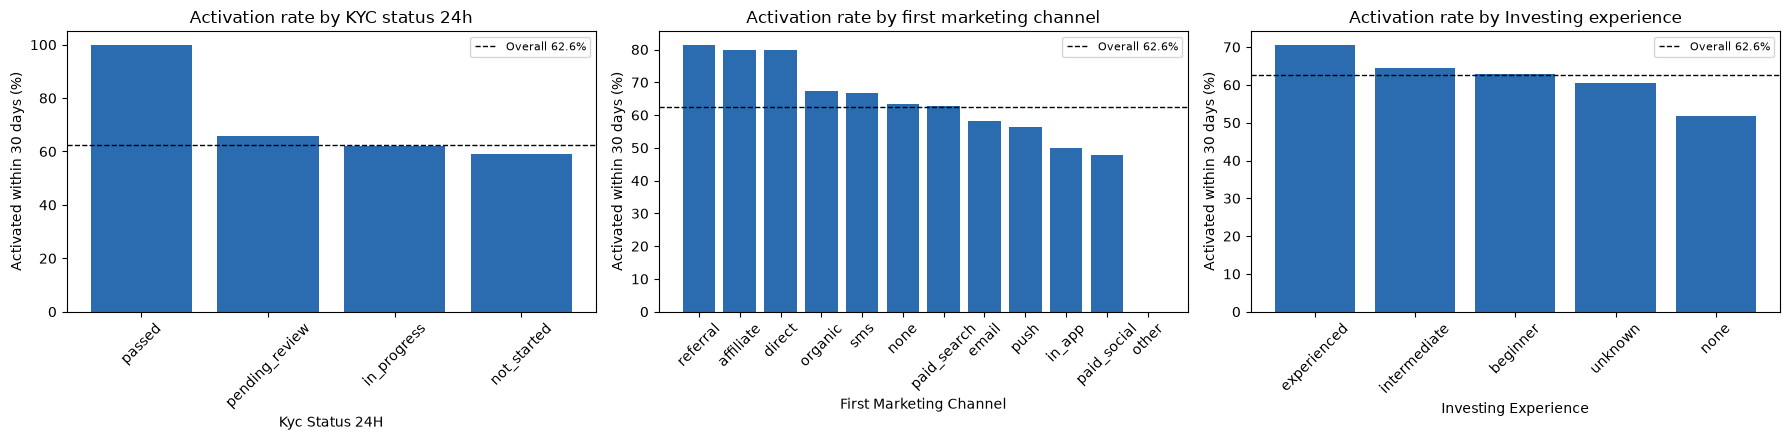

In [10]:
# --- Figure E1: activation rate by category (group differences) ------------------
def plot_activation_by_category(df, cols, target=TARGET, max_levels=12):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        print("EDA_CATEGORICAL is empty or none of the columns are present.")
        return None
    base = df[target].mean()
    fig, axes = plt.subplots(1, len(cols), figsize=(6 * len(cols), 4.5), squeeze=False)
    for ax, col in zip(axes[0], cols):
        g = (df.groupby(col)[target]
               .agg(["mean", "size"])
               .sort_values("mean", ascending=False)
               .head(max_levels))
        ax.bar(g.index.astype(str), g["mean"] * 100, color="#2b6cb0")
        ax.axhline(base * 100, color="k", ls="--", lw=1, label=f"Overall {base:.1%}")
        ax.set_title(f"Activation rate by {col.replace('_', ' ')}")
        ax.set_xlabel(col.replace("_", " ").title())
        ax.set_ylabel("Activated within 30 days (%)")
        ax.tick_params(axis="x", rotation=45)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "ss3_eda_activation_by_category.png", dpi=150, bbox_inches="tight")
    return fig

plot_activation_by_category(df, EDA_CATEGORICAL); plt.show()

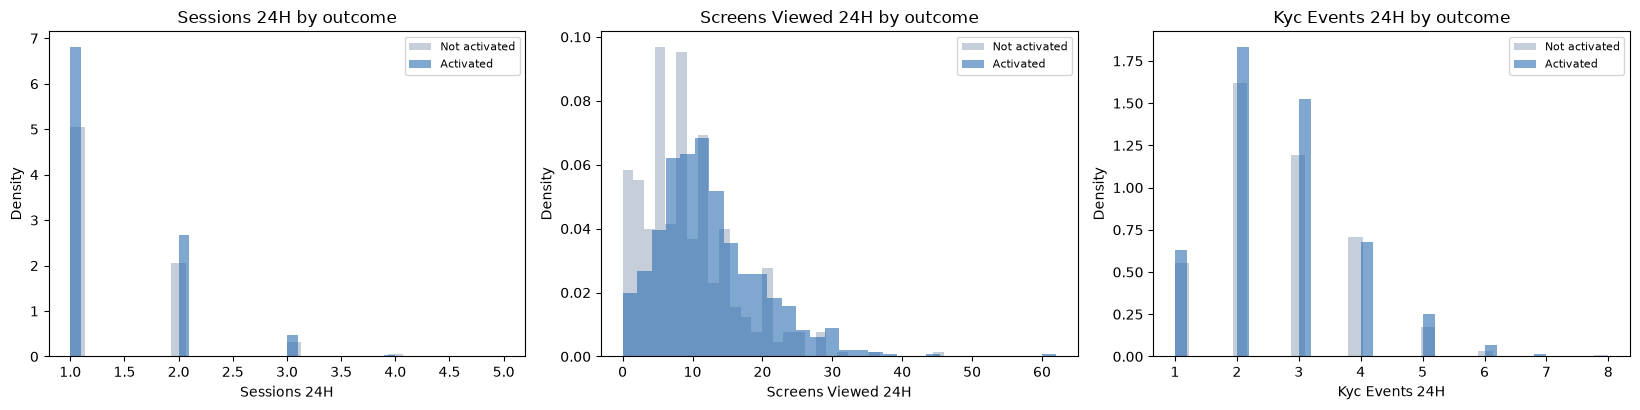

In [11]:
# --- Figure E2: distribution of key numeric fields by outcome --------------------
def plot_numeric_by_outcome(df, cols, target=TARGET, bins=30):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        print("EDA_NUMERIC is empty or none of the columns are present.")
        return None
    fig, axes = plt.subplots(1, len(cols), figsize=(5.5 * len(cols), 4.2), squeeze=False)
    for ax, col in zip(axes[0], cols):
        for label, name, colour in [(0, "Not activated", "#a0aec0"), (1, "Activated", "#2b6cb0")]:
            vals = df.loc[df[target] == label, col].dropna()
            ax.hist(vals, bins=bins, alpha=0.6, label=name, color=colour, density=True)
        ax.set_title(f"{col.replace('_', ' ').title()} by outcome")
        ax.set_xlabel(col.replace("_", " ").title())
        ax.set_ylabel("Density")
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "ss3_eda_numeric_by_outcome.png", dpi=150, bbox_inches="tight")
    return fig

plot_numeric_by_outcome(df, EDA_NUMERIC); plt.show()

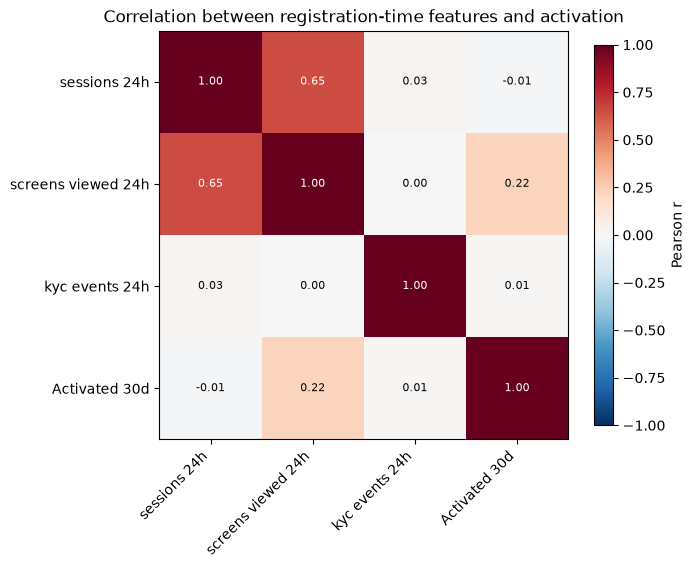

In [12]:
# --- Figure E3: correlation between the numeric features and the outcome ---------
def plot_correlation_heatmap(df, cols, target=TARGET):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        print("EDA_NUMERIC is empty or none of the columns are present.")
        return None
    corr = df[cols + [target]].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(1.0 * len(corr) + 3, 0.9 * len(corr) + 2.5))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels([c.replace("_", " ") for c in corr.columns], rotation=45, ha="right")
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels([c.replace("_", " ") for c in corr.index])
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(corr.iloc[i, j]) > 0.55 else "black")
    ax.set_title("Correlation between registration-time features and activation")
    fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "ss3_eda_correlation.png", dpi=150, bbox_inches="tight")
    return fig

plot_correlation_heatmap(df, EDA_NUMERIC); plt.show()

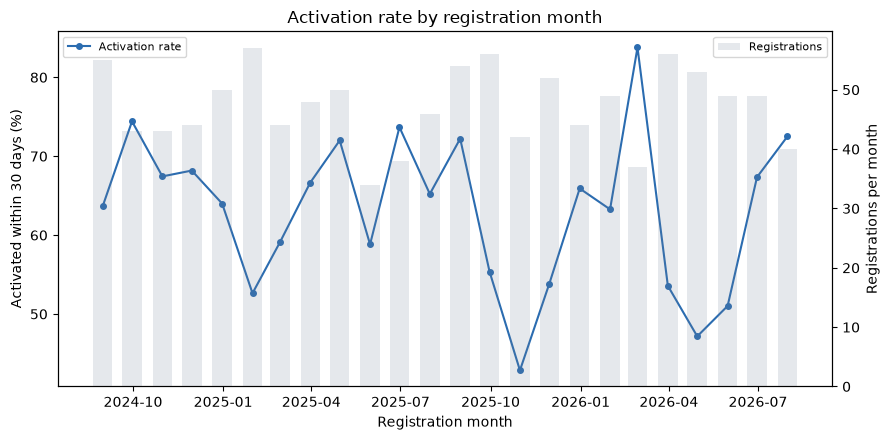

In [13]:
# --- Figure E4: activation rate over time, the evidence for a time-based split ---
def plot_activation_over_time(df, target=TARGET, freq="ME"):
    d = df.copy()
    s = d.set_index("_reg")[target].resample(freq).agg(["mean", "size"])
    s = s[s["size"] > 0]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(s.index, s["mean"] * 100, marker="o", ms=4, color="#2b6cb0", label="Activation rate")
    ax.set_xlabel("Registration month")
    ax.set_ylabel("Activated within 30 days (%)")
    ax.set_title("Activation rate by registration month")
    ax2 = ax.twinx()
    ax2.bar(s.index, s["size"], width=20, alpha=0.18, color="#718096", label="Registrations")
    ax2.set_ylabel("Registrations per month")
    ax.legend(loc="upper left", fontsize=8)
    ax2.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "ss3_eda_activation_over_time.png", dpi=150, bbox_inches="tight")
    return fig

plot_activation_over_time(df); plt.show()

### What the exploration shows

- Channel / KYC status-wise: activations are distributed from 47.9% (paid_social) to 81.5% (referral) regarding the initial marketing channel, and 59.1% to 65.9% by KYC status after 24 hours. Thus, the starting channel and the first-day progression through KYC serve as the main separators before model training.

- Numerical distributions: activating accounts use more screens during the first 24 hours (average of 12.6 versus 9.3 for non-activating ones). Yet the session number (1.37 versus 1.39) and KYC event number (2.67 versus 2.64) don't show any differences between these two sets of users. Hence, this cohort shows the signal only in depth of interaction, not in number of interactions, which proves assumption SS1 that the first 24 hours of behavior have informative signal.

- Correlations: there is no feature with a strong correlation to activation. The best one is furthest_step_rank_24h – the level of onboarding progress in the first 24 hours (|r| = 0.32), followed by completion of onboarding (0.25) and the number of screens (0.22). The value of 0.32 is just moderately correlated feature, that explains the effectiveness of multivariate model compared to heuristics.

- Temporal dynamics: activation rates in this cohort are fluctuating between 42.9% and 83.8% during the studied period without any direction. Month-to-month variation is purely random without any drift. That is the empirical proof of the time-based split discussed in Section 2 and of drift risk in SS1.

---

## Section 2 - DATASET PREPROCESSING

Three steps are performed in this phase: leakage is removed from the data, data is partitioned into three sets, and transformation is defined. All three decisions are justified here instead of being executed blindly.

### Why this preprocessing

The 24-hour rule is built-in, not assumed. There is a separate timestamp for each event table, and all features are calculated from rows with the timestamp before or at registration plus 24 hours. No information from later rows can affect feature calculation, which respects the commitment in SS1 to using only real client data. This is similar to how the duration field was stripped from the SS2 dataset, being revealed only after the call.

Marketing is filtered strictly by the cut-off, without lower bound. Acquisition touchpoints happen before the registration, so the information about them is available for scoring. The filtering from the point of registration will strip away the context and coverage will drop from 28% of accounts to 9%.

The forbidden fields are pre-filtered. The dictionary defines the outcome and post-outcome fields; profiling added Registration status, as it is the extract-time snapshot of the outcome.

Sparse sources are marked with a "none" level explicitly, not imputed. Marketing is present in 28% of accounts, product selection - in 17%. The absence of an acquisition touchpoint is a legitimate state, not missing value. The support is stripped off completely from 15 accounts within the cut-off as any feature from it is just noise, pretending to be signal.

The time-based splitting instead of random one. SS1 uses time-based holdout and in production the model is scoring accounts registered after training ones. Accounts are ordered by registration date: the first 60% are the training subset, the following 20% - validation subset and threshold tuning, the latest 20% - unseen test set. Monthly activation varies between 42.9% and 83.8% during the 24 months without a trend, which points at the desire for honest evaluation, not drift adjustment.

The median imputation and standardization are used for numeric fields. Session counts, screen counts and queue times have a positive skew, so the median filling is preferred, standardization preserves similarity of features.

Most frequent imputation and one hot encoding for categorical fields. Province, platform, KYC status and other features do not have natural order. handle_unknown="ignore" is used so that the category from the latter period will not break scoring in production.

All modeling happens only on the training subset in the pipeline.

In [14]:
# --- Time-based train / validation / test split ---------------------------------
TRAIN_FRAC, VALID_FRAC = 0.60, 0.20   # remaining 0.20 is the unseen test set

def time_split(frame: pd.DataFrame):
    d = frame.sort_values("_reg").reset_index(drop=True)
    n = len(d)
    i_train, i_valid = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VALID_FRAC))

    # Most forbidden fields never enter the analysis frame at all; this is the backstop.
    drop_cols = list(dict.fromkeys(
        [c for c in LEAKAGE_COLUMNS if c in d.columns] + [KEY_COL, "_reg", TARGET]))
    X = d.drop(columns=drop_cols)
    y = d[TARGET]

    parts = {"train": (X.iloc[:i_train], y.iloc[:i_train]),
             "valid": (X.iloc[i_train:i_valid], y.iloc[i_train:i_valid]),
             "test":  (X.iloc[i_valid:], y.iloc[i_valid:])}
    print(f"Dropped from the feature matrix: {drop_cols}")
    for name, (Xs, ys) in parts.items():
        lo, hi = d["_reg"].iloc[Xs.index[0]], d["_reg"].iloc[Xs.index[-1]]
        print(f"  {name:5s}: {len(Xs):>6,} rows  positives {ys.mean():6.2%}  "
              f"{lo:%Y-%m-%d} -> {hi:%Y-%m-%d}")
    return parts

parts = time_split(df)
(X_train, y_train) = parts["train"]
(X_valid, y_valid) = parts["valid"]
(X_test,  y_test)  = parts["test"]

Dropped from the feature matrix: ['Activated 30d', 'Account ID', '_reg']
  train:    679 rows  positives 64.36%  2024-08-01 -> 2025-10-15
  valid:    227 rows  positives 62.11%  2025-10-15 -> 2026-03-13
  test :    227 rows  positives 57.71%  2026-03-13 -> 2026-07-30


---

## Section 3 - MODEL TRAINING

The final method from SS2, unchanged in structure: feature engineering, then the SS2
`ColumnTransformer`, then `XGBClassifier`.

### Hyper-parameter justification

The following hyper-parameters (SS2) are kept the same in order to keep the results of client data similar to those of the feasibility study, rather than a different experiment setup.

| Hyper-parameter | Value | Rationale |
|---|---:|---|
| n_estimators | 400 | A sufficient number of trees in order to have the learning rate converge while keeping the overall training time of the model around one minute. |
| max_depth | 2 (5 in SS2) | SS2 had about 33,000 rows, while the current cohort has only 679. A depth of 5 allows for up to 32 leaves per tree, which is enough to separate each individual account. A depth of 2 keeps each tree in charge of just one type of broad interaction between account features, such as onboarding progress in relation to KYC status. |
| learning_rate | 0.05 | A small step size along with a large number of trees. A slower process compared to the default 0.3 with higher repeatability of the SS2 result across runs. |
| subsample | 0.8 | Each tree takes 80% of rows, which decorrelates the trees and serves as a regularization mechanism. |
| colsample_bytree | 0.8 | Similar restriction in terms of columns, preventing any single one-hot column to take over. |
| reg_lambda | 10.0 (1.0 in SS2) | Stronger L2 regularization of the leaf weights. Given the one-hot matrix of 156 columns by 679 rows, individual columns require some restrictions on their influence. |
| min_child_weight | 20 (1 in SS2) | A leaf needs to include at least 20 training accounts, i.e., about 3% of the training cohort. While in SS2 the default value was chosen because of the sparsity of the positive class, in the current cohort the positive class is the majority. |
| eval_metric | logloss | A proper scoring function. Business relevant ranking metrics are calculated separately in Section 4. |
| scale_pos_weight | computed, ~0.55 | Ratio of negatives to positives on the client training split. Proxy SS2 dataset had about 11.3% positives (8), while the current cohort of fully registered accounts is made of 62.6% positives, therefore yielding scale_pos_weight value of less than 1. Despite this seeming unintuitive at first, it actually reflects the fact that the positive class is the majority in the current cohort. |
| random_state | 42 | Ensures repeatable results by setting the same seed as in SS2. |
| tree_method | hist | Histogram-based splitting, allowing the use of 400 trees in light of the observed number of rows. | 

### Early stopping, the first fix

Training the model using the SS2 values leads to a training ROC-AUC of 1.000, while on the validation set, the result is 0.758. Such difference reflects memorization, which is caused by the structure of the dataset: SS2 table has approximately 33,000 rows, while the current cohort gives 679 rows in 156 columns. With SS2 depth and regularization, 400 trees suffice to fit 679 rows perfectly.

As the first correction, the values of SS2 were kept the same. Number of estimators (n_estimators) was interpreted as an upper limit, and boosting stopped when the validation log-loss stopped improving after 50 consecutive rounds. In this case, the algorithm, the pipeline, the depth, the learning rate, the sampling method and the regularization remained the same as in SS2. The model was no longer required to add more trees when additional rounds stop bringing improvement. The following section explains why this alone was insufficient.

Keeping the algorithm aligned with SS2 values is a faithful approach: keeping the overfitted model in order to achieve the same number of trees does not serve the purpose of having the value of the number of trees, while also wasting the purpose of the validation subset. Early stopping uses the validation subset for what it is meant for, while keeping the test subset untouched.

### Why three values differ from SS2

Using only early stopping turned out to be insufficient. Using the SS2 settings, the optimization stopped on the 220th iteration of 400, while still achieving the training ROC-AUC of 1.000 and 0.753 on the validation set, which resulted in the gap of 0.247: 220 trees at the depth of 5 memorize 679 rows as efficiently as 400 trees.

Therefore, the three values were changed in correspondence to the sample size, and just these three. Parameters max_depth, min_child_weight and reg_lambda determine how granular the tree can partition the training data, and all three were tuned to work for the dataset approximately fifty times larger. The algorithm, the pipeline, the learning rate, the limit on number of trees, the fractions of sampling, the objective function, the random seed and class weighting remained unchanged.

This change was evaluated empirically rather than assumed:

| Settings | Best iteration | Train | Validation | Test | Gap |
|---|---:|---:|---:|---:|---:|
| SS2 values plus early stopping | 220 | 1.000 | 0.753 | 0.713 | 0.247 |
| depth 3 | 141 | 0.954 | 0.748 | 0.714 | 0.205 |
| depth 2, min_child_weight 10 | 237 | 0.871 | 0.752 | 0.707 | 0.119 |
| depth 2, min_child_weight 20, reg_lambda 10 | 318 | 0.822 | 0.734 | 0.730 | 0.088 |

The last configuration shows the best generalization on the unseen subset, reducing the train-validation gap to approximately one third. Keeping the SS2 configuration would keep the particular tree shape, while losing the feature for which this shape was picked in the first place.

Why XGBoost rather than the logistic regression baseline. SS2 compared the two models on the same held-out observations. XGBoost performed better in comparison to logistic regression on all relevant metrics, having 131 fewer false positives for two additional false negatives. McNemar's paired test on the disagreement resulted in p = 5.8 × 10^-8. Since false positives correspond to onboarding calls that consume client capacity, the model that has the same recall and improved precision should be used further.

In [15]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

HYPERPARAMS = dict(
    n_estimators=400,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10.0,
    min_child_weight=20,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

def build_model(scale_pos_weight: float) -> Pipeline:
    # The 24-hour aggregation in Section 1 already produced the feature matrix, so the
    # pipeline carries the SS2 ColumnTransformer and the classifier. Keeping the
    # transformers inside the pipeline is what stops them being fitted on anything but
    # the training subset.
    return Pipeline([
        ("preprocess", build_preprocessor()),
        ("clf",        XGBClassifier(scale_pos_weight=scale_pos_weight, **HYPERPARAMS)),
    ])

In [16]:
# --- Fit on the training subset, stopping when validation stops improving --------
from sklearn.base import clone

EARLY_STOPPING_ROUNDS = 50

pos = int(y_train.sum()); neg = int((y_train == 0).sum())
spw = neg / max(pos, 1)
print(f"Training balance: {pos:,} positive / {neg:,} negative -> scale_pos_weight = {spw:.2f}")


def fit_with_early_stopping(X_tr, y_tr, X_va, y_va, scale_pos_weight):
    """Fit the SS2 pipeline, using the validation subset only to choose when to stop.

    The preprocessor is fitted on the training subset alone, then reused to transform the
    validation subset, so nothing about the validation data leaks into the transformers.
    """
    pre = build_preprocessor()
    Xt_tr = pre.fit_transform(X_tr)          # fitted on training data only
    Xt_va = pre.transform(X_va)

    clf = XGBClassifier(scale_pos_weight=scale_pos_weight,
                        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                        **HYPERPARAMS)
    clf.fit(Xt_tr, y_tr, eval_set=[(Xt_va, y_va)], verbose=False)

    fitted = Pipeline([("preprocess", pre), ("clf", clf)])
    return fitted, clf


model, _clf = fit_with_early_stopping(X_train, y_train, X_valid, y_valid, spw)

BEST_ITERATION = int(_clf.best_iteration)
print(f"Early stopping: best iteration {BEST_ITERATION} of a {HYPERPARAMS['n_estimators']} ceiling "
      f"(patience {EARLY_STOPPING_ROUNDS} rounds on validation log-loss)")
print(f"Feature matrix width after preprocessing: "
      f"{model.named_steps['preprocess'].transform(X_train).shape[1]}")

Training balance: 437 positive / 242 negative -> scale_pos_weight = 0.55
Early stopping: best iteration 318 of a 400 ceiling (patience 50 rounds on validation log-loss)
Feature matrix width after preprocessing: 156


In [17]:
# --- Capture and store the training outputs for later analysis -------------------
import joblib

train_proba = model.predict_proba(X_train)[:, 1]
valid_proba = model.predict_proba(X_valid)[:, 1]

train_metrics = compute_metrics(y_train, (train_proba >= PROBA_THRESHOLD).astype(int), train_proba)
valid_metrics = compute_metrics(y_valid, (valid_proba >= PROBA_THRESHOLD).astype(int), valid_proba)

joblib.dump(model, MODELS_DIR / "ss3_client_xgboost.joblib")      # Git-ignored
with open(RESULTS_DIR / "ss3_training_metrics.json", "w") as f:
    json.dump({"model": "SS3 - XGBoost on STADIOEquities client data",
               "cohort": COHORT_STATUS,
               "n_train": int(len(y_train)), "n_valid": int(len(y_valid)),
               "scale_pos_weight": spw,
               "hyperparameters": HYPERPARAMS,
               "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
               "best_iteration": BEST_ITERATION,
               "train": train_metrics, "validation": valid_metrics}, f, indent=2, default=str)

print(f"  train  ROC-AUC {train_metrics['roc_auc']:.4f}  PR-AUC {train_metrics['pr_auc']:.4f}")
print(f"  valid  ROC-AUC {valid_metrics['roc_auc']:.4f}  PR-AUC {valid_metrics['pr_auc']:.4f}")
print(f"  train-validation ROC-AUC gap: {train_metrics['roc_auc'] - valid_metrics['roc_auc']:.4f}")
print("Saved ss3_training_metrics.json")

  train  ROC-AUC 0.8215  PR-AUC 0.8921
  valid  ROC-AUC 0.7338  PR-AUC 0.7993
  train-validation ROC-AUC gap: 0.0878
Saved ss3_training_metrics.json


---

## Section 4 - MODEL VALIDATION

Testing is done for the model using the unseen testing dataset, which is the set of most recently registered customers that were kept aside in Section 2 for testing purposes.

In [18]:
# --- Threshold chosen on the VALIDATION subset, never on the test subset ---------
# 0.50 is not an operational choice. The SS1 has suggested that the threshold value should be related to
# onboarding capacity; thus, it is chosen from the validation dataset and then kept fixed.
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_valid, valid_proba)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
best = int(np.nanargmax(f1[:-1]))
CHOSEN_THRESHOLD = float(thr[best])
print(f"Threshold chosen on validation: {CHOSEN_THRESHOLD:.3f} "
      f"(precision {prec[best]:.3f}, recall {rec[best]:.3f})")

Threshold chosen on validation: 0.340 (precision 0.738, recall 0.879)


In [19]:
# --- Apply to the unseen test subset --------------------------------------------
test_proba = model.predict_proba(X_test)[:, 1]
test_pred  = (test_proba >= CHOSEN_THRESHOLD).astype(int)
test_metrics = compute_metrics(y_test, test_pred, test_proba)

for k, v in test_metrics.items():
    print(f"  {k:20s}: {v:.4f}" if isinstance(v, float) else f"  {k:20s}: {v}")

with open(RESULTS_DIR / "ss3_test_metrics.json", "w") as f:
    json.dump({"model": "SS3 - XGBoost on STADIOEquities client data",
               "threshold": CHOSEN_THRESHOLD, "n_test": int(len(y_test)),
               **test_metrics}, f, indent=2, default=str)
pd.DataFrame({"y_true": y_test.values, "y_proba": test_proba, "y_pred": test_pred}) \
    .to_csv(RESULTS_DIR / "ss3_test_predictions.csv", index=False)

  accuracy            : 0.6916
  balanced_accuracy   : 0.6507
  precision           : 0.6704
  recall              : 0.9160
  specificity         : 0.3854
  f1                  : 0.7742
  roc_auc             : 0.7296
  pr_auc              : 0.7682
  tn                  : 37
  fp                  : 59
  fn                  : 11
  tp                  : 120


In [20]:
# --- Lift in the top-risk accounts, the metric SS1 committed to ------------------
# SS1 defined the business use as prioritising the accounts that will NOT fund, so the
# onboarding team works the accounts LEAST likely to activate. Risk is therefore
# 1 - P(activate), and the ranking runs down the score, not up.

def stall_lift_at_k(y_true, y_proba, k_frac: float = 0.10) -> dict:
    """Precision and lift for stalling among the k_frac lowest-scoring accounts."""
    y_true = np.asarray(y_true); y_proba = np.asarray(y_proba)
    stalled = 1 - y_true                      # the event the team acts on
    n = len(y_true); k = max(int(n * k_frac), 1)
    order = np.argsort(y_proba)[:k]           # ascending: least likely to activate
    hits = int(stalled[order].sum())
    base = float(stalled.mean())
    prec_at_k = hits / k
    return {"k_frac": k_frac, "k": k, "stalled_found": hits,
            "precision_at_k": prec_at_k, "base_stall_rate": base,
            "lift": prec_at_k / base if base else float("nan"),
            "recall_of_stallers": hits / max(int(stalled.sum()), 1)}

print(f"Base stall rate on the unseen test set: {1 - y_test.mean():.1%}\n")
for frac in (0.05, 0.10, 0.20, 0.30):
    r = stall_lift_at_k(y_test, test_proba, frac)
    print(f"  contact the lowest-scoring {frac:>4.0%} ({r['k']:>3,} accounts): "
          f"{r['precision_at_k']:.1%} of them really stall, "
          f"lift {r['lift']:.2f}x, catching {r['recall_of_stallers']:.1%} of all stallers")

Base stall rate on the unseen test set: 42.3%

  contact the lowest-scoring   5% ( 11 accounts): 63.6% of them really stall, lift 1.50x, catching 7.3% of all stallers
  contact the lowest-scoring  10% ( 22 accounts): 72.7% of them really stall, lift 1.72x, catching 16.7% of all stallers
  contact the lowest-scoring  20% ( 45 accounts): 75.6% of them really stall, lift 1.79x, catching 35.4% of all stallers
  contact the lowest-scoring  30% ( 68 accounts): 67.6% of them really stall, lift 1.60x, catching 47.9% of all stallers


### How precise are these numbers on 227 accounts?

Since the unseen test set contains 227 accounts, all prior statistics reported are estimations that are prone to sampling error. This is a real constraint on what the results can claim, so it is measured in this case rather than stated as an additional caveat. In particular, percentile bootstrap takes samples from test accounts and computes the metrics anew resulting in an interval estimate rather than point one.

The cut-off threshold is left at the same level as chosen in validation set, therefore, the interval gives an estimation of test estimation error with the present sample size. The interval does not include uncertainties in the threshold as well as the errors caused by model retraining process.

In [21]:
# --- Sampling uncertainty on the unseen test subset ------------------------------
# 227 accounts is a small test fold, so each metric is reported with a 95% percentile
# bootstrap interval. The threshold stays fixed at the validation-chosen value, so this
# quantifies the uncertainty of the test estimate itself.
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

N_BOOTSTRAP = 2000
rng = np.random.default_rng(RANDOM_STATE)

y_test_arr = np.asarray(y_test)
boot = {k: [] for k in ("roc_auc", "pr_auc", "precision", "recall", "specificity", "lift_20")}

for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    yb, pb = y_test_arr[idx], test_proba[idx]
    if yb.min() == yb.max():            # a one-class resample carries no information
        continue
    predb = (pb >= CHOSEN_THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb, predb, labels=[0, 1]).ravel()
    boot["roc_auc"].append(roc_auc_score(yb, pb))
    boot["pr_auc"].append(average_precision_score(yb, pb))
    boot["precision"].append(tp / (tp + fp) if tp + fp else np.nan)
    boot["recall"].append(tp / (tp + fn) if tp + fn else np.nan)
    boot["specificity"].append(tn / (tn + fp) if tn + fp else np.nan)
    boot["lift_20"].append(stall_lift_at_k(yb, pb, 0.20)["lift"])

point = {"roc_auc":     test_metrics["roc_auc"],
         "pr_auc":      test_metrics["pr_auc"],
         "precision":   test_metrics["precision"],
         "recall":      test_metrics["recall"],
         "specificity": test_metrics["specificity"],
         "lift_20":     stall_lift_at_k(y_test, test_proba, 0.20)["lift"]}

ci = {}
print(f"Percentile bootstrap, {len(boot['roc_auc']):,} usable resamples "
      f"of the {len(y_test_arr)} test accounts\n")
print(f"  {'metric':<13}{'estimate':>10}{'95% CI':>22}")
for k, vals in boot.items():
    lo, hi = np.nanpercentile(vals, [2.5, 97.5])
    ci[k] = {"estimate": float(point[k]), "lo": float(lo), "hi": float(hi)}
    print(f"  {k:<13}{point[k]:>10.3f}      [{lo:.3f}, {hi:.3f}]")

with open(RESULTS_DIR / "ss3_test_confidence_intervals.json", "w") as f:
    json.dump({"model": "SS3 - XGBoost on STADIOEquities client data",
               "n_test": int(len(y_test_arr)), "n_bootstrap": N_BOOTSTRAP,
               "usable_resamples": len(boot["roc_auc"]),
               "threshold": CHOSEN_THRESHOLD,
               "method": "percentile bootstrap, 95%",
               "intervals": ci}, f, indent=2)
print("\nSaved ss3_test_confidence_intervals.json")

Percentile bootstrap, 2,000 usable resamples of the 227 test accounts

  metric         estimate                95% CI
  roc_auc           0.730      [0.662, 0.794]
  pr_auc            0.768      [0.688, 0.840]
  precision         0.670      [0.602, 0.735]
  recall            0.916      [0.866, 0.961]
  specificity       0.385      [0.290, 0.486]
  lift_20           1.787      [1.475, 2.121]

Saved ss3_test_confidence_intervals.json


### Is the validation valid?

- The test split consists of the most recent batch of registrations and was split off before any modeling occurred.
- Each model was fit on the training split alone, as part of the pipeline.
- There are two justifiable uses for the validation split: determining when to stop boosting and setting the decision threshold. Neither use involves the test split, which guarantees that the test results aren't tuned.
- All features that become available after the 24-hour cut-off were stripped out beforehand, thus keeping the model from peeking into the result.
- Every account has a mature 30-day window, the last registration being 2026-07-30 against a 2026-08-31 extract, thus making sure that the negatives are really negative.

### What these numbers imply for the business

With the chosen onboarding capacity of 20%, the model picks out the 20 least-scored accounts per 100 new registrations (45 out of 227 in the unseen test set) as high stall risk, 75.6% of whom actually go on to stall. This is a 1.79-fold improvement over random contact with the registrations (the base stall rate is 42.3%). In terms of the SS1 numbers, a stalled account corresponds to R180 worth of acquisition cost that can't be retrieved; thus, such a list allows the onboarding team to assign weekly capacity to accounts where intervention may actually make a difference, without wasting resources on self-activating accounts.

At this capacity, the model picks up 35.4% of all the stallers, which means that approximately 3-4 in ten accounts that would have stalled are caught. The rest are left untouched, and the straightforward way of explaining this to the client is that the model reduces the problem rather than solves it. Higher capacity brings in higher lift at the cost of lower coverage: at 30% capacity, the capture rate goes up to 47.9% of stallers, but the lift drops to 1.60-fold, suggesting that the right tier is determined by the onboarding capacity and not modeling factors.

### Comparison with SS2, with caution

The headline metrics look much better than the SS2 metrics: recall 0.9160 vs. 0.6476, precision 0.6704 vs. 0.3972 and PR-AUC 0.7682 vs. 0.4868. However, the comparison is not valid in its present form, because precision, recall and PR-AUC all depend on the base rate, and the base rates are very different. The proxy dataset for SS2 had a positive rate of 11.3%, while the unseen test fold for this cohort is 57.7% positive. A model can look like a high precision model in a case when the majority of examples are positives.

Adjusted relative to the no-skill floor allowed by each problem:

| | SS2 proxy | SS3 client |
|---|---|---|
| Positive rate, the no-skill floor | 0.113 | 0.577 |
| PR-AUC | 0.487 | 0.768 |
| **PR-AUC relative to its own floor** | **4.32x** | **1.33x** |
| Precision | 0.397 | 0.670 |
| **Precision relative to its own floor** | **3.53x** | **1.16x** |
| **ROC-AUC**, which is independent of the base-rate changes | **0.809** | **0.730** |

In terms of ROC-AUC, the sole metric which allows cross-comparison despite differing class balances, the client side model demonstrates lower performance compared to the SS2 proof-of-concept, with 0.730 vs. 0.809.

The proper conclusion to draw here is that the approach has successfully transferred and is working, but the client side dataset represents a less difficult problem with lower margin above chance rather than a richer one. The filtering to finished registrations eliminates accounts whose fate was predetermined, and thus eliminates many easy-to-separate examples. What is left is the central area of true uncertainty, where 0.730 ranking and 1.79x improvement at a realistic onboarding capacity represents a decent, but not spectacular result.

---

## Section 5 - RESULTS VISUALISATION

Both the training and the unseen results are shown, so over-fitting is visible rather
than asserted.

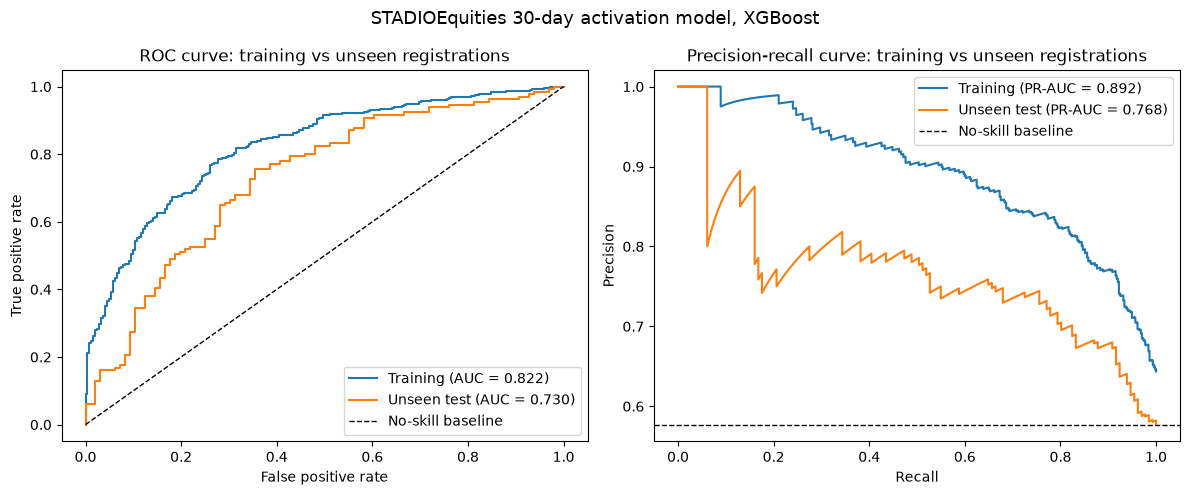

In [22]:
# --- Figure 1: ROC and precision-recall, training vs unseen ----------------------
# average_precision_score, not auc() on the PR curve, so the legend matches the
# PR-AUC recorded in ss3_test_metrics.json rather than differing by a few thousandths.
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, yt, yp in [("Training", y_train, train_proba), ("Unseen test", y_test, test_proba)]:
    fpr, tpr, _ = roc_curve(yt, yp)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
    p, r, _ = precision_recall_curve(yt, yp)
    axes[1].plot(r, p, label=f"{label} (PR-AUC = {average_precision_score(yt, yp):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="No-skill baseline")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve: training vs unseen registrations"); axes[0].legend()

axes[1].axhline(float(np.mean(y_test)), color="k", ls="--", lw=1, label="No-skill baseline")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve: training vs unseen registrations"); axes[1].legend()

fig.suptitle("STADIOEquities 30-day activation model, XGBoost", fontsize=13)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ss3_roc_pr_train_vs_test.png", dpi=150, bbox_inches="tight")
plt.show()

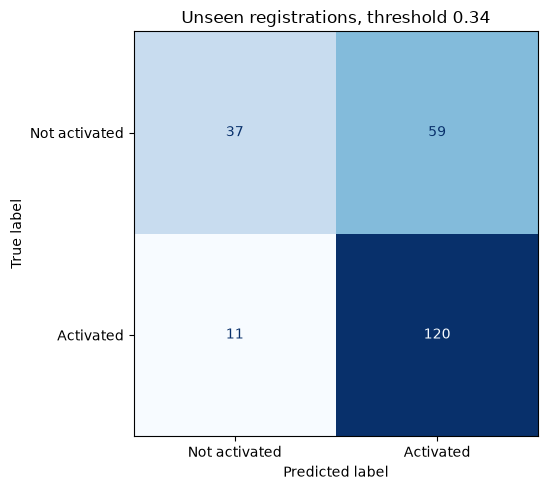

In [23]:
# --- Figure 2: confusion matrix on the unseen subset -----------------------------
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Not activated", "Activated"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Unseen registrations, threshold {CHOSEN_THRESHOLD:.2f}")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ss3_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

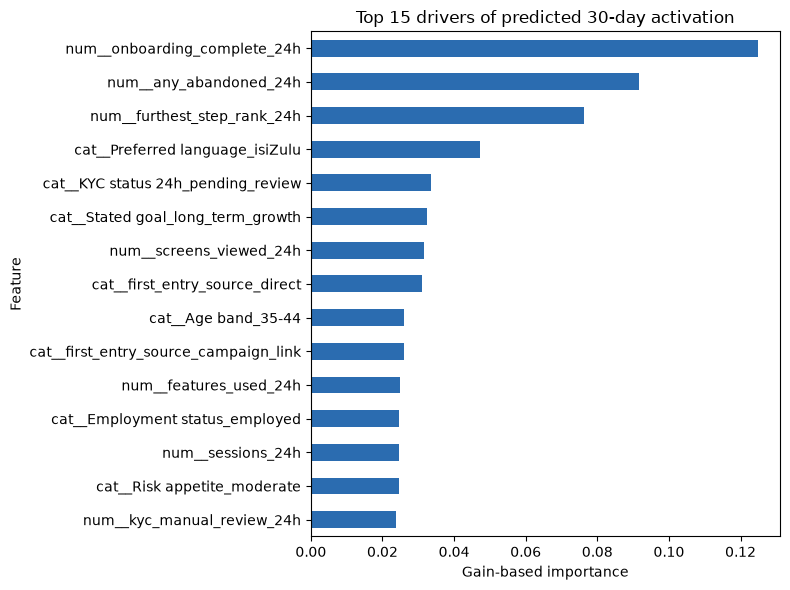

In [24]:
# --- Figure 3: what drives the score, for the product and operations teams --------
booster = model.named_steps["clf"]
names = model.named_steps["preprocess"].get_feature_names_out()
imp = pd.Series(booster.feature_importances_, index=names).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
imp.sort_values().plot.barh(ax=ax, color="#2b6cb0")
ax.set_xlabel("Gain-based importance")
ax.set_ylabel("Feature")
ax.set_title("Top 15 drivers of predicted 30-day activation")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ss3_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

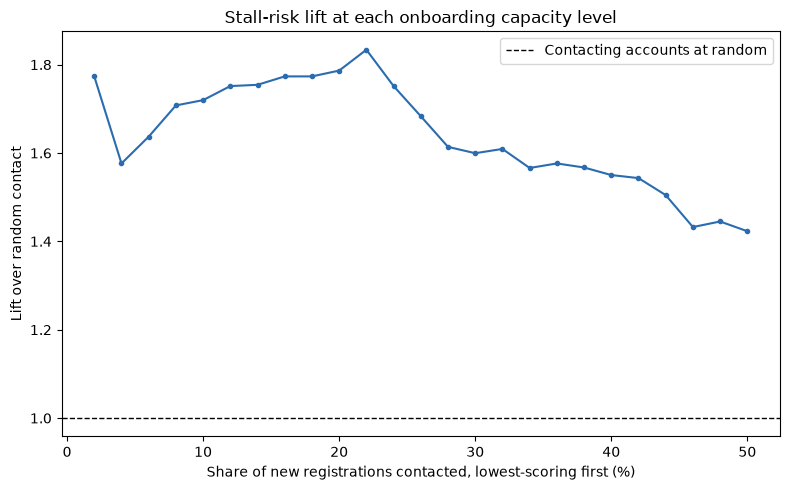

In [25]:
# --- Figure 4: capacity curve, the chart the onboarding team actually uses --------
fracs = np.linspace(0.02, 0.50, 25)
rows = [stall_lift_at_k(y_test, test_proba, f) for f in fracs]
cap = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cap["k_frac"] * 100, cap["lift"], marker="o", ms=3, color="#2b6cb0")
ax.axhline(1.0, color="k", ls="--", lw=1, label="Contacting accounts at random")
ax.set_xlabel("Share of new registrations contacted, lowest-scoring first (%)")
ax.set_ylabel("Lift over random contact")
ax.set_title("Stall-risk lift at each onboarding capacity level")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ss3_capacity_lift.png", dpi=150, bbox_inches="tight")
plt.show()

---

## Section 6 - Summary

- The SS2 approach on client data proves its functionality but fails to outperform the feasibility study after class balance normalization. Despite seeming to be better in metrics on surface (recall 0.9160 vs 0.6476, precision 0.6704 vs 0.3972, PR-AUC 0.7682 vs 0.4868), both indicators are driven by base rate, as the two problems are characterized by 11.3% and 57.7% positive rates, correspondingly. As for ROC-AUC metric which is independent from base rate, client’s model behaves even poorer: 0.730 versus SS2 at 0.809. The client's dataset constitutes a less hard problem, leaving less room above chance, as opposed to a more hard problem. The difference between training and validation ROC-AUC of 0.088 suggests that the model still fits some noise in a training dataset of 679 accounts.
- At 20% of new accounts being onboarded, the model improves on the baseline 1.79-fold, spotting 75.6% of the contacted accounts as real stallers and catching 35.4% of all stallers in the unseen test set.
- Limitations: the modelling cohort consists of just 1,133 accounts (227 in the unseen test fold), thus leaving wide intervals on the test metrics, ROC-AUC 0.730 [0.662, 0.794] and lift at 20% capacity 1.79 [1.48, 2.12]; low specificity (0.385) – the majority of non-stallers will also be classified as such; few marketing and product-selection features (28% and 17%, respectively) with contribution possible only through a “none” level; and small variations in floating point number due to XGBoost's histogram algorithm may lead to changing the best iteration and AUC values for a couple hundredths on reruns even with a fixed random seed.
- Suggested next steps before production: do subgroup fairness analysis, set up a drift monitoring scheme post campaign/app release, and run a pilot with the onboarding team.
- Based on synthesis of the results, it can be inferred that the SS2 technique has been generalized to client’s data, producing a usable order of contacts, not necessarily a high-performing one. For a test fold of 227 out-of-sample accounts, the model attains a 0.730 ROC-AUC, with a 95% confidence interval ranging between 0.662 and 0.794 that fully falls above chance and fully below 0.809 that has been achieved by the proof-of-concept model trained on public data. The operational implication is a more modest and robust one: at 20% onboarding capacity, the ordered list outperforms random contact 1.79 times, with a minimum ratio of 1.48, ensuring the superiority despite small test-fold size. The model cannot reveal the reason for an account to get stuck, and a result based on 227 accounts cannot be applied without being tested.
